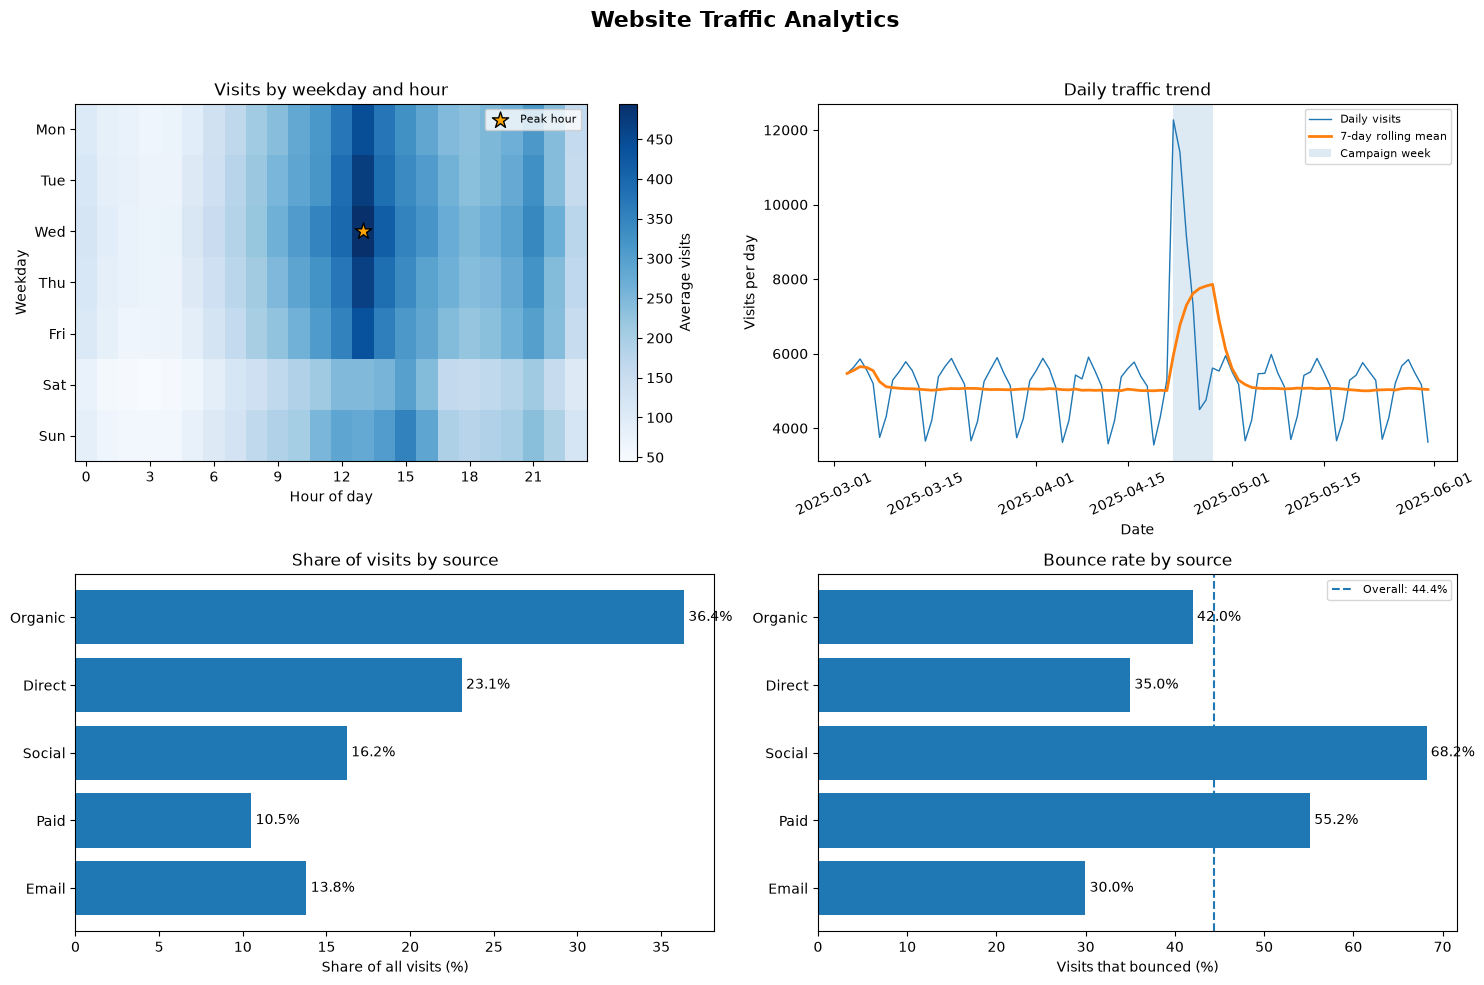


WEBSITE TRAFFIC ANALYTICS RESULTS
Dataset rows: 10800
Unique hourly timestamps: 2160
Total visits: 474,620
Average visits per day: 5,273.56
Peak hour: 13:00
Campaign day visits: 12,270

Traffic source summary:
         visits  share_percent  bounce_percent
source                                        
Direct   109580          23.09           34.99
Email     65509          13.80           29.97
Organic  172614          36.37           42.01
Paid      49894          10.51           55.15
Social    77023          16.23           68.21

Files created:
1. website_traffic_dataset.csv
2. chart.png
3. results.json


In [5]:
# Project 26: Website Traffic Analytics

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Generate dataset
def build_traffic_data(seed=26):
    rng = np.random.default_rng(seed)

    timestamps = pd.date_range(
        start="2025-03-03",
        periods=90 * 24,
        freq="h"
    )

    hours = timestamps.hour.to_numpy()
    weekdays = timestamps.dayofweek.to_numpy()
    day_numbers = np.arange(len(timestamps)) // 24

    weekday_factors = np.array([
        1.05, 1.08, 1.15, 1.08, 1.02, 0.70, 0.82
    ])

    hour_factors = np.array([
        0.45, 0.35, 0.30, 0.28, 0.30, 0.40,
        0.55, 0.70, 0.85, 1.00, 1.15, 1.30,
        1.50, 1.85, 1.55, 1.35, 1.20, 1.05,
        0.95, 1.00, 1.10, 1.30, 1.00, 0.65
    ])

    daily_factor = weekday_factors[weekdays]
    hourly_factor = hour_factors[hours].copy()

    weekend = weekdays >= 5
    hourly_factor[weekend & (hours == 13)] = 1.50
    hourly_factor[weekend & (hours == 14)] = 1.60
    hourly_factor[weekend & (hours == 15)] = 1.85
    hourly_factor[weekend & (hours == 16)] = 1.50

    sources = ["Organic", "Direct", "Social", "Paid", "Email"]

    shares = {
        "Organic": 0.38,
        "Direct": 0.24,
        "Social": 0.17,
        "Paid": 0.09,
        "Email": 0.12
    }

    bounce_probabilities = {
        "Organic": 0.42,
        "Direct": 0.351,
        "Social": 0.68,
        "Paid": 0.551,
        "Email": 0.299
    }

    campaign = np.zeros(90)
    campaign[50:57] = [6.0, 4.5, 3.0, 2.0, 1.2, 0.6, 0.2]

    expected_total = 230 * daily_factor * hourly_factor
    rows = []

    for i, timestamp in enumerate(timestamps):
        for source in sources:
            multiplier = 1.0

            if source in ("Email", "Paid"):
                multiplier += campaign[day_numbers[i]]

            expected = expected_total[i] * shares[source] * multiplier
            visits = int(rng.poisson(expected))
            bounces = int(
                rng.binomial(visits, bounce_probabilities[source])
            )

            rows.append({
                "time": timestamp,
                "source": source,
                "visits": visits,
                "bounces": bounces
            })

    df = pd.DataFrame(rows)
    df["date"] = df["time"].dt.floor("D")
    df["hour"] = df["time"].dt.hour
    df["weekday"] = df["time"].dt.day_name().str[:3]

    return df


# 2. Analyze traffic
def analyze_traffic(df):
    hourly = (
        df.groupby("time", as_index=False)["visits"]
        .sum()
        .sort_values("time")
    )

    hourly["rolling_7day"] = (
        hourly["visits"].rolling(168, min_periods=1).mean()
    )

    daily = df.groupby("date")["visits"].sum().sort_index()

    campaign_date = pd.Timestamp("2025-04-22")
    campaign_visits = int(daily.loc[campaign_date])
    median_daily = float(daily.median())
    campaign_lift = campaign_visits / median_daily

    # Exclude campaign week from baseline calculations.
    hourly_details = (
        df.groupby(
            ["time", "date", "hour", "weekday"],
            as_index=False
        )["visits"].sum()
    )

    baseline = hourly_details[
        (hourly_details["date"] < campaign_date) |
        (hourly_details["date"] >= pd.Timestamp("2025-04-29"))
    ]

    peak_by_hour = baseline.groupby("hour")["visits"].mean()
    peak_hour = int(peak_by_hour.idxmax())
    peak_average = float(peak_by_hour.max())

    weekday_order = [
        "Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"
    ]

    heatmap = (
        baseline.groupby(["weekday", "hour"])["visits"]
        .mean()
        .unstack("hour")
        .reindex(index=weekday_order, columns=range(24))
    )

    sources = df.groupby("source").agg(
        visits=("visits", "sum"),
        bounces=("bounces", "sum")
    )

    total_visits = int(sources["visits"].sum())

    sources["share_percent"] = (
        sources["visits"] / total_visits * 100
    )

    sources["bounce_percent"] = (
        sources["bounces"] / sources["visits"] * 100
    ).fillna(0)

    return {
        "hourly": hourly,
        "daily": daily,
        "heatmap": heatmap,
        "sources": sources,
        "total_visits": total_visits,
        "average_daily": float(daily.mean()),
        "peak_hour": peak_hour,
        "peak_average": peak_average,
        "campaign_date": campaign_date,
        "campaign_visits": campaign_visits,
        "median_daily": median_daily,
        "campaign_lift": campaign_lift
    }


# 3. Draw all four charts
def make_chart(result):
    heatmap = result["heatmap"]
    daily = result["daily"]
    sources = result["sources"]

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(
        "Website Traffic Analytics",
        fontsize=16,
        fontweight="bold"
    )

    # Chart 1: Heatmap
    ax = axes[0, 0]

    image = ax.imshow(
        heatmap.to_numpy(),
        aspect="auto",
        origin="upper",
        cmap="Blues"
    )

    ax.set_title("Visits by weekday and hour")
    ax.set_xlabel("Hour of day")
    ax.set_ylabel("Weekday")
    ax.set_xticks(range(0, 24, 3))
    ax.set_yticks(range(7))
    ax.set_yticklabels(heatmap.index)

    ax.scatter(
        [result["peak_hour"]],
        [2],
        marker="*",
        s=150,
        color="orange",
        edgecolors="black",
        label="Peak hour"
    )

    ax.legend(fontsize=8)
    fig.colorbar(image, ax=ax, label="Average visits")

    # Chart 2: Daily trend
    ax = axes[0, 1]

    ax.plot(
        daily.index,
        daily.values,
        linewidth=1,
        label="Daily visits"
    )

    rolling = daily.rolling(7, min_periods=1).mean()

    ax.plot(
        rolling.index,
        rolling.values,
        linewidth=2,
        label="7-day rolling mean"
    )

    ax.axvspan(
        result["campaign_date"],
        result["campaign_date"] + pd.Timedelta(days=6),
        alpha=0.15,
        label="Campaign week"
    )

    ax.set_title("Daily traffic trend")
    ax.set_xlabel("Date")
    ax.set_ylabel("Visits per day")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=8)

    # Chart 3: Traffic source share
    ax = axes[1, 0]

    order = ["Organic", "Direct", "Social", "Paid", "Email"]
    shares = sources.reindex(order)["share_percent"]

    bars = ax.barh(order, shares)
    ax.invert_yaxis()
    ax.set_title("Share of visits by source")
    ax.set_xlabel("Share of all visits (%)")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

    # Chart 4: Bounce rate
    ax = axes[1, 1]

    bounce = sources.reindex(order)["bounce_percent"]
    bars = ax.barh(order, bounce)
    ax.invert_yaxis()

    overall_bounce = (
        sources["bounces"].sum() /
        sources["visits"].sum() * 100
    )

    ax.axvline(
        overall_bounce,
        linestyle="--",
        label=f"Overall: {overall_bounce:.1f}%"
    )

    ax.set_title("Bounce rate by source")
    ax.set_xlabel("Visits that bounced (%)")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.legend(fontsize=8)

    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig("chart.png", dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# 4. Main program
def main():
    df = build_traffic_data(seed=26)

    # Save the dataset
    df.to_csv("website_traffic_dataset.csv", index=False)

    result = analyze_traffic(df)

    # Generate dashboard
    make_chart(result)

    sources = result["sources"]

    # Save findings to JSON
    results = {
        "total_visits": result["total_visits"],
        "average_visits_per_day": round(result["average_daily"], 2),
        "peak_hour": f'{result["peak_hour"]:02d}:00',
        "average_visits_at_peak_hour": round(result["peak_average"], 2),
        "campaign_date": str(result["campaign_date"].date()),
        "campaign_day_visits": result["campaign_visits"],
        "median_daily_visits": round(result["median_daily"], 2),
        "campaign_day_vs_median": round(result["campaign_lift"], 2),
        "traffic_source_share_percent": sources["share_percent"].round(2).to_dict(),
        "bounce_rate_percent": sources["bounce_percent"].round(2).to_dict()
    }

    with open("results.json", "w", encoding="utf-8") as file:
        json.dump(results, file, indent=4)

    print("\nWEBSITE TRAFFIC ANALYTICS RESULTS")
    print("=" * 40)
    print("Dataset rows:", len(df))
    print("Unique hourly timestamps:", df["time"].nunique())
    print(f'Total visits: {result["total_visits"]:,}')
    print(f'Average visits per day: {result["average_daily"]:,.2f}')
    print(f'Peak hour: {result["peak_hour"]:02d}:00')
    print(f'Campaign day visits: {result["campaign_visits"]:,}')

    print("\nTraffic source summary:")
    print(
        sources[["visits", "share_percent", "bounce_percent"]]
        .round(2)
        .to_string()
    )

    print("\nFiles created:")
    print("1. website_traffic_dataset.csv")
    print("2. chart.png")
    print("3. results.json")


if __name__ == "__main__":
    main()